# SECOM Yield Analysis — Exploratory Data Analysis

## Goal

Explore what the dataset shows before building prediction models.

For each analysis, I will record:

1. The question
2. The method
3. The observation
4. What the observation does and does not imply

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

data_dir = Path("../data/raw")

X = pd.read_csv(
    data_dir / "secom.data",
    sep=r"\s+",
    header=None
)
X.columns = [f"feature_{i}" for i in range(X.shape[1])]

labels = pd.read_csv(
    data_dir / "secom_labels.data",
    sep=r"\s+",
    header=None,
    names=["label", "timestamp_text"]
)

labels["timestamp"] = pd.to_datetime(
    labels["timestamp_text"],
    format="%d/%m/%Y %H:%M:%S",
    errors="coerce"
)

assert len(X) == len(labels)
assert X.index.equals(labels.index)
assert labels["timestamp"].notna().all()

df = pd.concat([X, labels[["label", "timestamp"]]], axis=1)

print("Data shape:", df.shape)

Data shape: (1567, 592)


## 1. Class Distribution

### Question

How imbalanced are the Pass and Fail classes?

### Relevance to the UCI Baseline

The UCI baseline reports True Positive rate, True Negative rate, and Balanced Error Rate. Examining the class distribution helps explain why class-specific metrics are needed instead of relying only on overall accuracy.

In [4]:
class_counts = df["label"].value_counts().reindex([-1, 1])

class_summary = pd.DataFrame({
    "count": class_counts,
    "percentage": class_counts / len(df) * 100
})

class_summary.index = ["Pass (-1)", "Fail (1)"]
class_summary.round(2)

,count,percentage
Pass (-1),1463,93.36
Fail (1),104,6.64


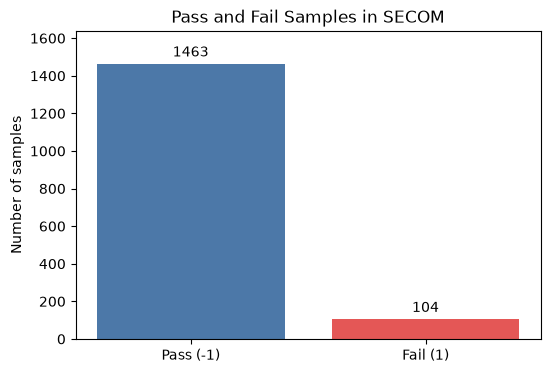

In [5]:
fig, ax = plt.subplots(figsize=(6, 4))

bars = ax.bar(
    class_summary.index,
    class_summary["count"],
    color=["#4C78A8", "#E45756"]
)

ax.bar_label(bars, padding=3)
ax.set_title("Pass and Fail Samples in SECOM")
ax.set_ylabel("Number of samples")
ax.set_ylim(0, class_summary["count"].max() * 1.12)

plt.show()

### Observation

The dataset contains 1,463 Pass samples and 104 Fail samples. Fail accounts for approximately 6.64% of the dataset.

An Always-Pass rule would achieve approximately 93.36% accuracy while detecting none of the 104 Fail samples. Therefore, accuracy alone is insufficient.

For later evaluation:

- Fail detection rate measures how many actual Fail samples are detected.
- Pass detection rate measures how many actual Pass samples are correctly identified.
- Balanced Error Rate gives equal importance to errors in the two classes.

### Limitation

The 93.36% Pass proportion describes this dataset. It should not automatically be interpreted as the yield of an entire manufacturing line because the dataset does not explain how the 1,567 samples were selected from total production.

## 2. Illustrative Feature Scales and Distributions

### Question

Do example measurement features use similar numerical scales?

### Relevance to the UCI Baseline

The UCI baseline standardizes the measurement features before classification. These examples illustrate why features measured on different numerical scales may require standardization.

The three features were selected by column position for illustration. They were not selected for predictive importance and should not be assumed to represent all 590 features.

In [9]:
selected_features = ["feature_0", "feature_1", "feature_4"]

In [10]:
X[selected_features].describe().T

,count,mean,std,min,25%,50%,75%,max
feature_0,1561.0,3014.452896,73.621787,2743.2400,2966.2600,3011.4900,3056.6500,3356.3500
feature_1,1560.0,2495.850231,80.407705,2158.7500,2452.2475,2499.4050,2538.8225,2846.4400
feature_4,1553.0,4.197013,56.355540,0.6815,1.0177,1.3168,1.5257,1114.5366


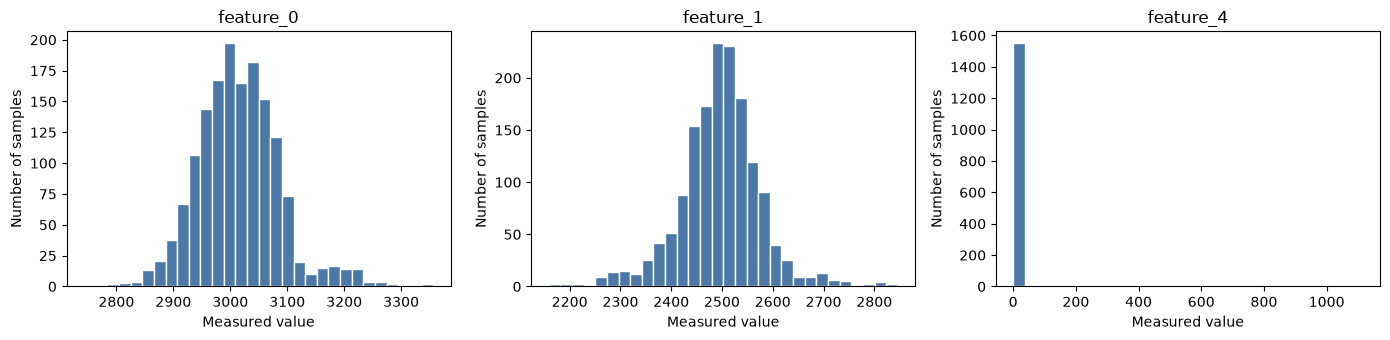

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))

for ax, feature in zip(axes, selected_features):
    ax.hist(
        X[feature].dropna(),
        bins=30,
        color="#4C78A8",
        edgecolor="white"
    )
    ax.set_title(feature)
    ax.set_xlabel("Measured value")
    ax.set_ylabel("Number of samples")

fig.tight_layout()
plt.show()

### Observation

The selected features have different numerical scales. The median values of `feature_0` and `feature_1` are approximately 3011 and 2499, while the median of `feature_4` is approximately 1.32.

`feature_4` also contains a value far above most of its observed values. This example shows that some feature distributions may be affected by extreme recorded values.

These examples support examining feature scales before modeling. They do not establish predictive importance, measurement error, or the physical meaning of any feature.

These three features were selected by column position as illustrative examples. Their distributions should not be assumed to represent all 590 features, and they were not selected for predictive importance.

## 3. EDA Summary for the UCI Baseline

### Main Findings

1. **Class imbalance**

   The dataset contains 1,463 Pass samples and 104 Fail samples. Fail accounts for approximately 6.64% of all samples.

   An Always-Pass rule would achieve approximately 93.36% accuracy while detecting none of the Fail samples. Therefore, accuracy alone is insufficient for evaluating this classification task.

2. **Different feature scales**

   The illustrative features have different numerical ranges. For example, the median values of `feature_0` and `feature_1` are approximately 3011 and 2499, while the median of `feature_4` is approximately 1.32.

   This supports the standardization step used in the UCI baseline. The three selected features are illustrative examples and should not be assumed to represent all 590 features.

3. **Data-quality findings from the previous audit**

   The feature matrix contains missing values, and 116 features have only one distinct observed value when missing values are ignored.

   These findings support the need for missing-value handling and constant-feature removal before classification.

### Connection to the UCI Baseline

The EDA and data audit provide the following logic for the baseline workflow:

- Class imbalance motivates the use of class-specific performance measures and Balanced Error Rate.
- Different numerical scales motivate feature standardization.
- Missing values require an imputation strategy before the classifier can be fitted.
- Constant observed features require a constant-feature removal step.
- The UCI baseline selects 40 features before fitting a Kernel Ridge classifier.

All preprocessing and feature-selection steps will be fitted within each cross-validation training fold to prevent data leakage.

The next stage will follow the UCI recommendation and use 10-fold cross-validation.

## 4. Supplementary EDA

The following analyses provide additional context but do not determine the primary UCI baseline protocol.

### 4.1 Daily Time Distribution

**Question:** How many samples and Fail outcomes were recorded on each date?

**Purpose:** Examine daily sample counts and Fail proportions.

**Role in this project:** This is supplementary context. The primary baseline evaluation follows the UCI recommendation and uses 10-fold cross-validation.

In [3]:
daily_data = labels[["timestamp", "label"]].copy()
daily_data["date"] = daily_data["timestamp"].dt.date

daily_summary = (
    daily_data
    .groupby("date")["label"]
    .agg(
        total_samples="size",
        fail_samples=lambda values: (values == 1).sum()
    )
)

daily_summary["fail_rate_pct"] = (
    daily_summary["fail_samples"]
    / daily_summary["total_samples"]
    * 100
)

daily_summary.head()

,total_samples,fail_samples,fail_rate_pct
date,,,
2008-07-19,12,3,25.0
2008-07-20,1,0,0.0
2008-07-21,2,1,50.0
2008-07-22,6,0,0.0
2008-07-23,2,0,0.0


#### Daily Interpretation

Some dates contain very few samples. Therefore, a high daily Fail percentage may be produced by only one or two Fail samples.

The daily Fail percentage must be interpreted together with the daily sample count. This analysis describes variation within the dataset and does not prove that a manufacturing yield excursion occurred.

### 4.2 Weekly Time Distribution

Daily Fail percentages can be unstable when only a few samples are recorded on a date. The weekly summary combines several dates to provide a broader view.

Both weekly sample count and weekly Fail percentage are displayed because a percentage is less stable when its sample count is small.

In [4]:
weekly_summary = (
    labels[["timestamp", "label"]]
    .set_index("timestamp")
    .resample("W")["label"]
    .agg(
        total_samples="size",
        fail_samples=lambda values: (values == 1).sum()
    )
)

weekly_summary["fail_rate_pct"] = (
    weekly_summary["fail_samples"]
    / weekly_summary["total_samples"]
    * 100
)

weekly_summary.head()

,total_samples,fail_samples,fail_rate_pct
timestamp,,,
2008-07-20,13,3,23.076923
2008-07-27,21,2,9.523810
2008-08-03,48,10,20.833333
2008-08-10,108,14,12.962963
2008-08-17,51,7,13.725490


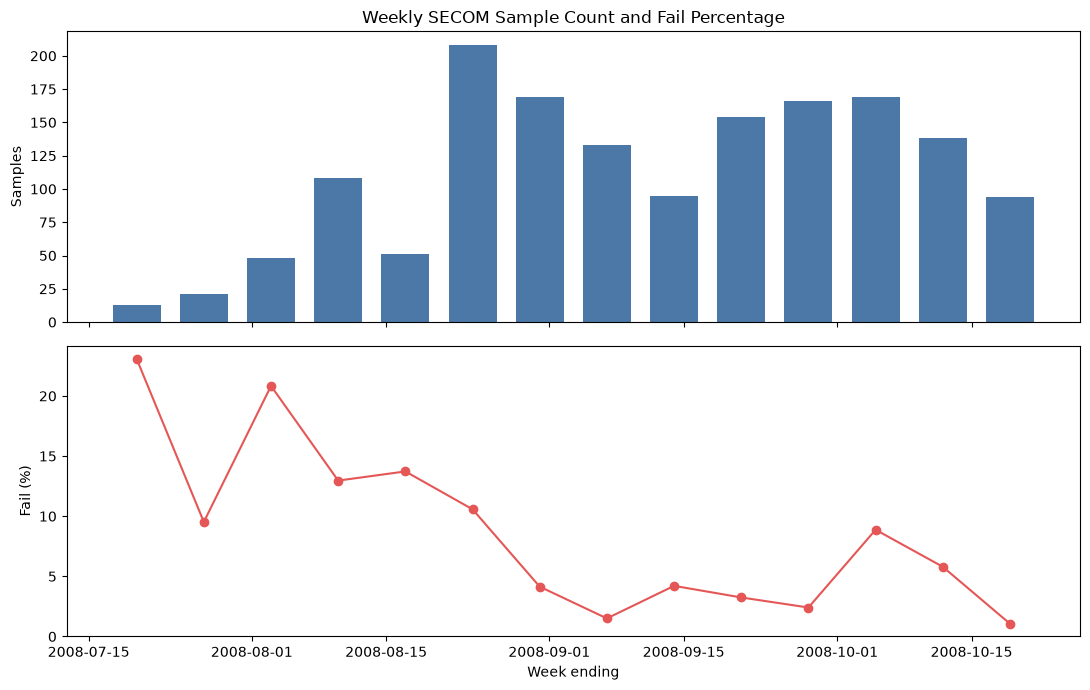

In [8]:
fig, axes = plt.subplots(
    2, 1,
    figsize=(11, 7),
    sharex=True
)

axes[0].bar(
    weekly_summary.index,
    weekly_summary["total_samples"],
    width=5,
    color="#4C78A8"
)
axes[0].set_ylabel("Samples")
axes[0].set_title("Weekly SECOM Sample Count and Fail Percentage")

axes[1].plot(
    weekly_summary.index,
    weekly_summary["fail_rate_pct"],
    marker="o",
    color="#E45756"
)
axes[1].set_ylabel("Fail (%)")
axes[1].set_xlabel("Week ending")
axes[1].set_ylim(bottom=0)

fig.tight_layout()
plt.show()

#### Weekly Interpretation

Weekly sample counts and Fail percentages vary over the recorded period. Some early weeks have relatively few samples, so their Fail percentages are sensitive to a small number of failures.

The weekly view is supplementary. It does not replace the UCI-recommended 10-fold cross-validation and does not establish the occurrence or cause of a yield excursion.

#### Observation

Recorded sample counts and Fail percentages vary by week. Weeks containing few samples can show unstable percentages because one Fail has a large effect on the calculated rate.

This observation does not establish a manufacturing yield excursion or explain its cause. It will not replace the UCI-recommended 10-fold cross-validation in the primary baseline experiment.

### 4.3 Extreme-Value Illustration

The full-range histogram of `feature_4` is compressed by a very large maximum value. The following plot displays values up to the 99th percentile to make the main concentration visible.

This changes only the displayed range. It does not remove observations from the dataset or classify values above the 99th percentile as errors.

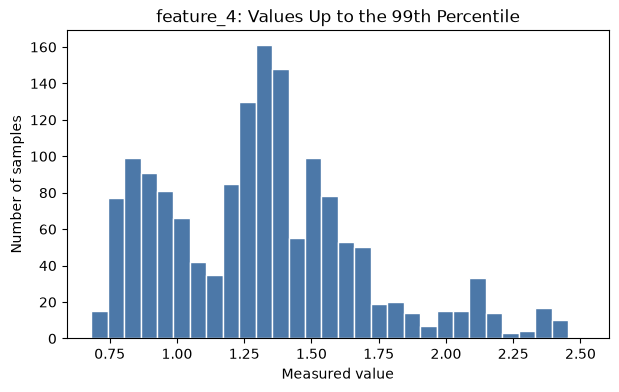

99th percentile: 2.525024


In [12]:
feature = "feature_4"
upper_limit = X[feature].quantile(0.99)

plt.figure(figsize=(7, 4))
plt.hist(
    X.loc[X[feature] <= upper_limit, feature].dropna(),
    bins=30,
    color="#4C78A8",
    edgecolor="white"
)
plt.title("feature_4: Values Up to the 99th Percentile")
plt.xlabel("Measured value")
plt.ylabel("Number of samples")
plt.show()

print("99th percentile:", upper_limit)

### 4.4 Dataset-Wide IQR Screening

To avoid generalizing from `feature_4` alone, the same descriptive high-value rule was applied to all 590 features.

A feature is flagged when its maximum exceeds `Q3 + 3 × IQR`, provided that its IQR is greater than zero. This is an exploratory screening rule, not part of the UCI baseline preprocessing.

In [13]:
q1 = X.quantile(0.25)
q3 = X.quantile(0.75)
iqr = q3 - q1

upper_bound = q3 + 3 * iqr

high_value_flag = (iqr > 0) & (X.max() > upper_bound)

print("Features checked:", X.shape[1])
print("Features with at least one flagged high value:", high_value_flag.sum())
print("Was feature_4 flagged?", high_value_flag["feature_4"])

Features checked: 590
Features with at least one flagged high value: 348
Was feature_4 flagged? True


Under this descriptive rule, 348 of 590 features contain at least one flagged high value, and `feature_4` is included.

This result does not prove that 348 features contain errors, and it will not be used to remove features or observations in the UCI baseline.